In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train_df = pd.read_csv(
    "train.txt", sep=";", header=None,
    names=["text", "emotion"]
)

val_df = pd.read_csv(
    "val.txt", sep=";", header=None,
    names=["text", "emotion"]
)

test_df = pd.read_csv(
    "test.txt", sep=";", header=None,
    names=["text", "emotion"]
)

print(train_df.head())
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)


print(train_df.head(10))

print("\nEmotion Classes:")
print(train_df["emotion"].unique())

print("\nEmotion Distribution:")
print(train_df["emotion"].value_counts())

print("\nMissing Values:")
print(train_df.isnull().sum())

      

                                                text  emotion
0                            i didnt feel humiliated  sadness
1  i can go from feeling so hopeless to so damned...  sadness
2   im grabbing a minute to post i feel greedy wrong    anger
3  i am ever feeling nostalgic about the fireplac...     love
4                               i am feeling grouchy    anger
Training: (16000, 2)
Validation: (2000, 2)
Testing: (2000, 2)
                                                text   emotion
0                            i didnt feel humiliated   sadness
1  i can go from feeling so hopeless to so damned...   sadness
2   im grabbing a minute to post i feel greedy wrong     anger
3  i am ever feeling nostalgic about the fireplac...      love
4                               i am feeling grouchy     anger
5  ive been feeling a little burdened lately wasn...   sadness
6  ive been taking or milligrams or times recomme...  surprise
7  i feel as confused about life as a teenager or...      fear

In [2]:
# Check missing values
print("Training Missing Values:")
print(train_df.isnull().sum())

print("\nValidation Missing Values:")
print(val_df.isnull().sum())

print("\nTesting Missing Values:")
print(test_df.isnull().sum())

# Check duplicates
print("\nDuplicate Rows:")
print("Training:", train_df.duplicated().sum())
print("Validation:", val_df.duplicated().sum())
print("Testing:", test_df.duplicated().sum())


Training Missing Values:
text       0
emotion    0
dtype: int64

Validation Missing Values:
text       0
emotion    0
dtype: int64

Testing Missing Values:
text       0
emotion    0
dtype: int64

Duplicate Rows:
Training: 1
Validation: 0
Testing: 0


In [3]:
# Remove missing values
train_df = train_df.dropna().copy()
val_df = val_df.dropna().copy()
test_df = test_df.dropna().copy()

# Text cleaning function
def clean_text(text):
    text = text.lower()
    text = text.strip()
    text = " ".join(text.split())
    return text

# Apply cleaning
for df in [train_df, val_df, test_df]:
    df["text"] = df["text"].apply(clean_text)
    df["emotion"] = df["emotion"].str.strip().str.lower()

    # Remove empty text
    df.drop(df[df["text"] == ""].index, inplace=True)

print(train_df.head())


                                                text  emotion
0                            i didnt feel humiliated  sadness
1  i can go from feeling so hopeless to so damned...  sadness
2   im grabbing a minute to post i feel greedy wrong    anger
3  i am ever feeling nostalgic about the fireplac...     love
4                               i am feeling grouchy    anger


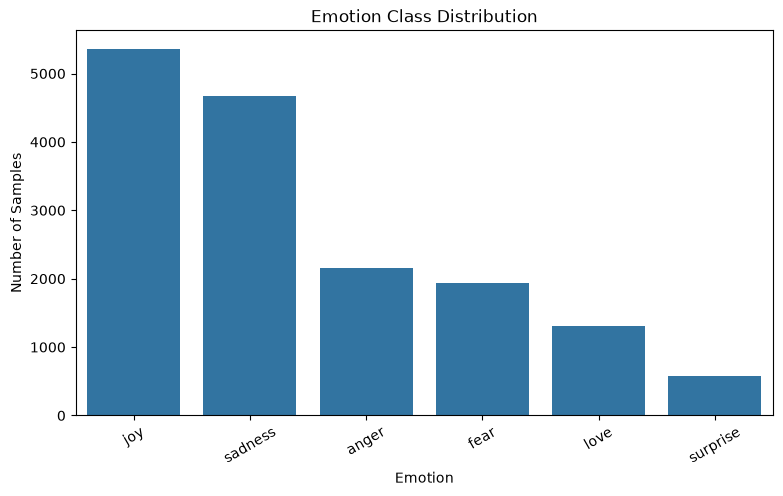

In [4]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=train_df,
    x="emotion",
    order=train_df["emotion"].value_counts().index
)

plt.title("Emotion Class Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30)
plt.show()

In [5]:
#Is our dataset balanced?
#If sadness has significantly more examples than surprise, 
#the network might become better at recognizing sadness simply because it has seen more examples.

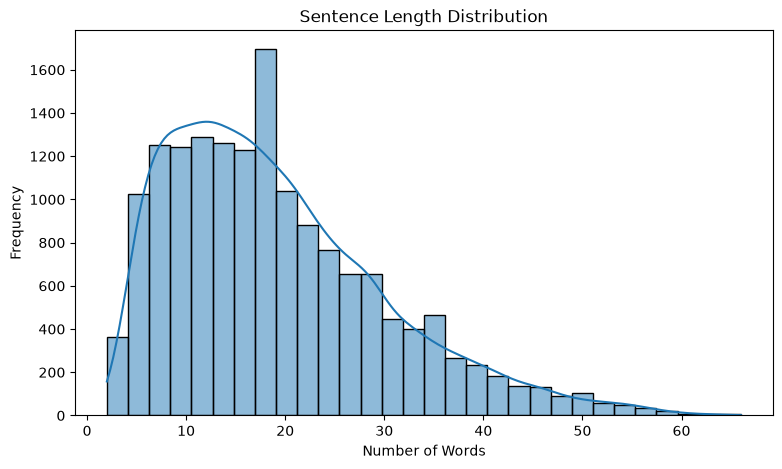

count    16000.000000
mean        19.166313
std         10.986905
min          2.000000
25%         11.000000
50%         17.000000
75%         25.000000
max         66.000000
Name: text_length, dtype: float64

95th Percentile:
41.0


In [6]:
#Analyze sentence lengths
# Calculate sentence length
train_df["text_length"] = train_df["text"].apply(
    lambda text: len(text.split())
)

# Visualize
plt.figure(figsize=(9, 5))

sns.histplot(
    train_df["text_length"],
    bins=30,
    kde=True
)

plt.title("Sentence Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

# Statistics
print(train_df["text_length"].describe())

print("\n95th Percentile:")
print(train_df["text_length"].quantile(0.95))


In [7]:
#data leakage check
train_texts = set(train_df["text"])
val_texts = set(val_df["text"])
test_texts = set(test_df["text"])

print("Train / Validation overlap:",
      len(train_texts & val_texts))

print("Train / Test overlap:",
      len(train_texts & test_texts))

print("Validation / Test overlap:",
      len(val_texts & test_texts))


Train / Validation overlap: 5
Train / Test overlap: 11
Validation / Test overlap: 3


In [8]:
#fixing the problems

# Remove duplicate sentences within each dataset
train_df = train_df.drop_duplicates(subset="text").copy()
val_df = val_df.drop_duplicates(subset="text").copy()
test_df = test_df.drop_duplicates(subset="text").copy()

# Remove validation sentences already in training
val_df = val_df[
    ~val_df["text"].isin(train_df["text"])
].copy()

# Remove test sentences already in training or validation
used_texts = set(train_df["text"]) | set(val_df["text"])

test_df = test_df[
    ~test_df["text"].isin(used_texts)
].copy()

# Reset indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

print("\nRemaining overlaps:")
print("Train / Validation:",
      len(set(train_df["text"]) & set(val_df["text"])))
print("Train / Test:",
      len(set(train_df["text"]) & set(test_df["text"])))
print("Validation / Test:",
      len(set(val_df["text"]) & set(test_df["text"])))


Training: (15969, 3)
Validation: (1993, 2)
Testing: (1986, 2)

Remaining overlaps:
Train / Validation: 0
Train / Test: 0
Validation / Test: 0


In [9]:
#NLP part

In [10]:
import tensorflow as tf

from tensorflow.keras.layers import TextVectorization
from sklearn.preprocessing import LabelEncoder

In [11]:
#Our models can't directly predict text labels such as "joy" or "sadness". We need numerical classes.

In [12]:
# Initialize label encoder
label_encoder = LabelEncoder()

# Fit only on training labels
y_train = label_encoder.fit_transform(train_df["emotion"])

# Transform validation and test labels
y_val = label_encoder.transform(val_df["emotion"])
y_test = label_encoder.transform(test_df["emotion"])

# Show emotion-to-number mapping
for i, emotion in enumerate(label_encoder.classes_):
    print(i, ":", emotion)

print("\nTraining labels:", y_train[:10])


0 : anger
1 : fear
2 : joy
3 : love
4 : sadness
5 : surprise

Training labels: [4 4 0 3 0 4 5 1 2 3]


In [13]:
#We'll use Keras TextVectorization to convert sentences into sequences of integers.

In [14]:
# Configuration
MAX_TOKENS = 10000
MAX_LENGTH = 50

# Initialize text vectorizer
vectorizer = TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=MAX_LENGTH,
    standardize=None
)

# Learn vocabulary from training data only
vectorizer.adapt(train_df["text"].values)

# Convert text into numerical sequences
X_train = vectorizer(train_df["text"].values).numpy()
X_val = vectorizer(val_df["text"].values).numpy()
X_test = vectorizer(test_df["text"].values).numpy()

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nOriginal sentence:")
print(train_df["text"].iloc[0])

print("\nTokenized and padded sentence:")
print(X_train[0])


Training: (15969, 50)
Validation: (1993, 50)
Testing: (1986, 50)

Original sentence:
i didnt feel humiliated

Tokenized and padded sentence:
[  2 139   3 685   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0]


In [15]:
vocabulary = vectorizer.get_vocabulary()

print("Vocabulary size:", len(vocabulary))

print("\nFirst 20 vocabulary entries:")
print(vocabulary[:20])

print("\nTraining data shape:", X_train.shape)
print("Training labels shape:", y_train.shape)


Vocabulary size: 10000

First 20 vocabulary entries:
['', '[UNK]', np.str_('i'), np.str_('feel'), np.str_('and'), np.str_('to'), np.str_('the'), np.str_('a'), np.str_('feeling'), np.str_('that'), np.str_('of'), np.str_('my'), np.str_('in'), np.str_('it'), np.str_('like'), np.str_('so'), np.str_('im'), np.str_('for'), np.str_('me'), np.str_('but')]

Training data shape: (15969, 50)
Training labels shape: (15969,)


In [16]:
#Build and Train the CNN Model

In [17]:
#Unlike the CNNs used for images, our CNN operates on sequences of word embeddings.

In [18]:
#Our CNN will learn useful patterns from the training data rather than relying on manually defined rules.

In [19]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Embedding, Conv1D,
    GlobalMaxPooling1D, Dropout, Dense
)
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

In [20]:
# Build CNN model
cnn_model = Sequential([
    Input(shape=(MAX_LENGTH,)),

    Embedding(
        input_dim=len(vocabulary),
        output_dim=100
    ),

    Conv1D(
        filters=64,
        kernel_size=3,
        activation="relu"
    ),

    GlobalMaxPooling1D(),

    Dropout(0.3),

    Dense(6, activation="softmax")
])

# Compile the model
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display architecture
cnn_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 100)        │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 48, 64)         │        19,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,019,654 (3.89 MB)

 Trainable params: 1,019,654 (3.89 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# Early stopping
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Train the model
cnn_history = cnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6563 - loss: 0.9567 - val_accuracy: 0.9202 - val_loss: 0.2223
Epoch 2/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9192 - loss: 0.2122 - val_accuracy: 0.9227 - val_loss: 0.1784
Epoch 3/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9422 - loss: 0.1519 - val_accuracy: 0.9242 - val_loss: 0.1787
Epoch 4/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9547 - loss: 0.1197 - val_accuracy: 0.9202 - val_loss: 0.1862
Epoch 5/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9688 - loss: 0.0879 - val_accuracy: 0.9217 - val_loss: 0.2068


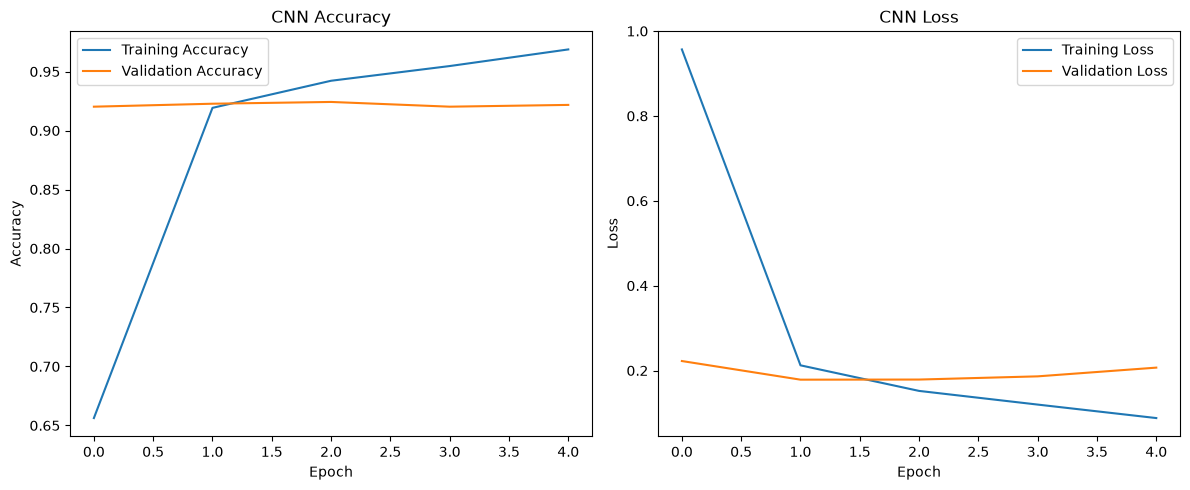

In [22]:
history = cnn_history.history

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history["accuracy"], label="Training Accuracy")
plt.plot(history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history["loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [23]:
from sklearn.metrics import classification_report

# Validation performance
val_loss, val_accuracy = cnn_model.evaluate(
    X_val, y_val, verbose=0
)

# Predicted probabilities
y_val_probs = cnn_model.predict(X_val)

# Predicted emotion class
y_val_pred = np.argmax(y_val_probs, axis=1)

print("CNN Validation Accuracy:", round(val_accuracy, 4))
print("CNN Validation Loss:", round(val_loss, 4))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
CNN Validation Accuracy: 0.9227
CNN Validation Loss: 0.1784

Classification Report:
              precision    recall  f1-score   support

       anger       0.92      0.92      0.92       274
        fear       0.88      0.85      0.87       212
         joy       0.96      0.93      0.95       701
        love       0.81      0.93      0.86       175
     sadness       0.94      0.96      0.95       550
    surprise       0.88      0.81      0.85        81

    accuracy                           0.92      1993
   macro avg       0.90      0.90      0.90      1993
weighted avg       0.92      0.92      0.92      1993



In [24]:
#saving the CNN network model
os.makedirs("models", exist_ok=True)

cnn_model.save("models/cnn_model.keras")

print("CNN model saved successfully!")


CNN model saved successfully!


In [25]:
#Build and Train the LSTM Model

In [26]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Embedding, LSTM, Dropout, Dense
)
from tensorflow.keras.callbacks import EarlyStopping


In [27]:
# Set random seed
tf.keras.utils.set_random_seed(42)

# Build LSTM model
lstm_model = Sequential([
    Input(shape=(MAX_LENGTH,)),

    Embedding(
        input_dim=len(vocabulary),
        output_dim=100,
        mask_zero=True
    ),

    LSTM(64),

    Dropout(0.3),

    Dense(6, activation="softmax")
])

# Compile model
lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Model summary
lstm_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 50, 100)        │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,042,630 (3.98 MB)

 Trainable params: 1,042,630 (3.98 MB)

 Non-trainable params: 0 (0.00 B)

In [28]:
# Early stopping
lstm_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Train LSTM
lstm_history = lstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=32,
    callbacks=[lstm_early_stop],
    verbose=1
)


Epoch 1/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.5698 - loss: 1.1421 - val_accuracy: 0.8324 - val_loss: 0.5527
Epoch 2/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.9023 - loss: 0.3128 - val_accuracy: 0.8951 - val_loss: 0.3430
Epoch 3/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9498 - loss: 0.1578 - val_accuracy: 0.9122 - val_loss: 0.2790
Epoch 4/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9686 - loss: 0.0958 - val_accuracy: 0.9102 - val_loss: 0.3046
Epoch 5/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9785 - loss: 0.0680 - val_accuracy: 0.9122 - val_loss: 0.3084
Epoch 6/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9795 - loss: 0.0639 - val_accuracy: 0.9112 - val_loss: 0.3011


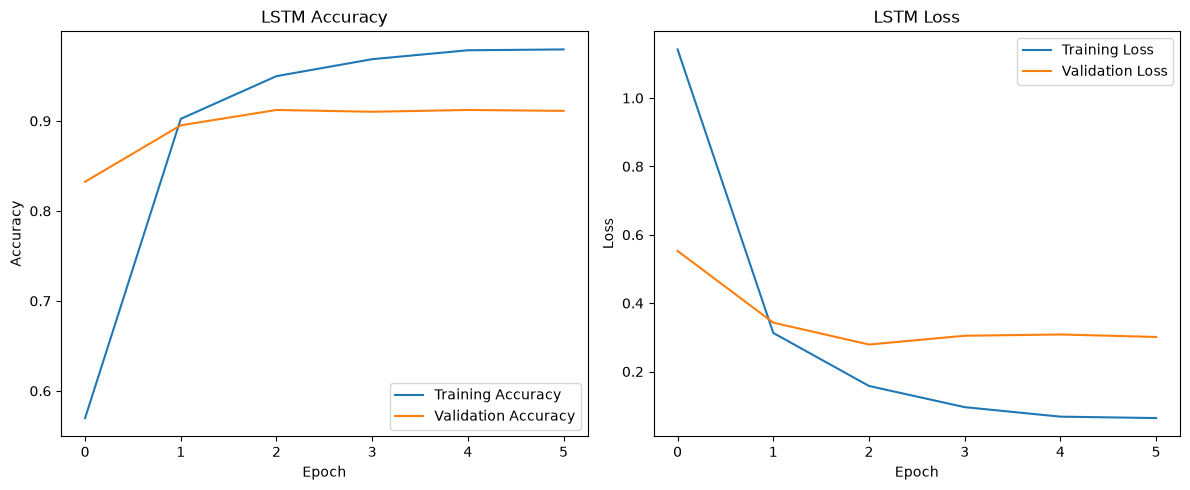

In [29]:
history = lstm_history.history

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history["accuracy"], label="Training Accuracy")
plt.plot(history["val_accuracy"], label="Validation Accuracy")
plt.title("LSTM Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history["loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.title("LSTM Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [30]:
from sklearn.metrics import classification_report

# Validation evaluation
lstm_val_loss, lstm_val_accuracy = lstm_model.evaluate(
    X_val, y_val, verbose=0
)

# Predictions
lstm_val_probs = lstm_model.predict(X_val)
lstm_val_pred = np.argmax(lstm_val_probs, axis=1)

print("LSTM Validation Accuracy:",
      round(lstm_val_accuracy, 4))

print("LSTM Validation Loss:",
      round(lstm_val_loss, 4))

print("\nLSTM Classification Report:")
print(classification_report(
    y_val,
    lstm_val_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
LSTM Validation Accuracy: 0.9122
LSTM Validation Loss: 0.279

LSTM Classification Report:
              precision    recall  f1-score   support

       anger       0.91      0.92      0.91       274
        fear       0.94      0.79      0.86       212
         joy       0.96      0.91      0.93       701
        love       0.77      0.93      0.84       175
     sadness       0.93      0.96      0.95       550
    surprise       0.74      0.88      0.80        81

    accuracy                           0.91      1993
   macro avg       0.88      0.90      0.88      1993
weighted avg       0.92      0.91      0.91      1993



In [31]:
from sklearn.metrics import f1_score

# CNN metrics
cnn_val_loss, cnn_val_accuracy = cnn_model.evaluate(
    X_val, y_val, verbose=0
)

cnn_val_pred = np.argmax(
    cnn_model.predict(X_val, verbose=0),
    axis=1
)

# Macro F1-scores
cnn_f1 = f1_score(
    y_val, cnn_val_pred, average="macro"
)

lstm_f1 = f1_score(
    y_val, lstm_val_pred, average="macro"
)

# Comparison table
comparison = pd.DataFrame({
    "Model": ["CNN", "LSTM"],
    "Validation Accuracy": [
        cnn_val_accuracy,
        lstm_val_accuracy
    ],
    "Validation Loss": [
        cnn_val_loss,
        lstm_val_loss
    ],
    "Macro F1": [
        cnn_f1,
        lstm_f1
    ]
})

print(comparison.round(4))


  Model  Validation Accuracy  Validation Loss  Macro F1
0   CNN               0.9227           0.1784    0.8982
1  LSTM               0.9122           0.2790    0.8825


In [32]:
import os

os.makedirs("models", exist_ok=True)

lstm_model.save("models/lstm_model.keras")

print("LSTM model saved successfully!")


LSTM model saved successfully!


In [33]:
#Final Model Evaluation

In [34]:
from sklearn.metrics import (
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

# Evaluate CNN
cnn_test_loss, cnn_test_acc = cnn_model.evaluate(
    X_test, y_test, verbose=0
)

cnn_test_probs = cnn_model.predict(X_test, verbose=0)
cnn_test_pred = np.argmax(cnn_test_probs, axis=1)

# Evaluate LSTM
lstm_test_loss, lstm_test_acc = lstm_model.evaluate(
    X_test, y_test, verbose=0
)

lstm_test_probs = lstm_model.predict(X_test, verbose=0)
lstm_test_pred = np.argmax(lstm_test_probs, axis=1)

# Create comparison table
test_comparison = pd.DataFrame({
    "Model": ["CNN", "LSTM"],
    "Accuracy": [cnn_test_acc, lstm_test_acc],
    "Loss": [cnn_test_loss, lstm_test_loss],
    "Precision": [
        precision_score(y_test, cnn_test_pred, average="macro", zero_division=0),
        precision_score(y_test, lstm_test_pred, average="macro", zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, cnn_test_pred, average="macro", zero_division=0),
        recall_score(y_test, lstm_test_pred, average="macro", zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, cnn_test_pred, average="macro"),
        f1_score(y_test, lstm_test_pred, average="macro")
    ]
})

print(test_comparison.round(4))


  Model  Accuracy    Loss  Precision  Recall  F1 Score
0   CNN    0.9245  0.1622     0.8695  0.8844    0.8760
1  LSTM    0.9124  0.2626     0.8560  0.8851    0.8666


In [35]:
print("===== CNN CLASSIFICATION REPORT =====")

print(classification_report(
    y_test,
    cnn_test_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))

print("\n===== LSTM CLASSIFICATION REPORT =====")

print(classification_report(
    y_test,
    lstm_test_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))


===== CNN CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

       anger       0.92      0.92      0.92       274
        fear       0.91      0.87      0.89       224
         joy       0.96      0.93      0.95       688
        love       0.78      0.91      0.84       156
     sadness       0.96      0.96      0.96       579
    surprise       0.68      0.71      0.69        65

    accuracy                           0.92      1986
   macro avg       0.87      0.88      0.88      1986
weighted avg       0.93      0.92      0.93      1986


===== LSTM CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

       anger       0.91      0.92      0.91       274
        fear       0.94      0.81      0.87       224
         joy       0.96      0.91      0.94       688
        love       0.74      0.91      0.82       156
     sadness       0.95      0.96      0.95       579
    surprise       0.63      0.80      0.71        65


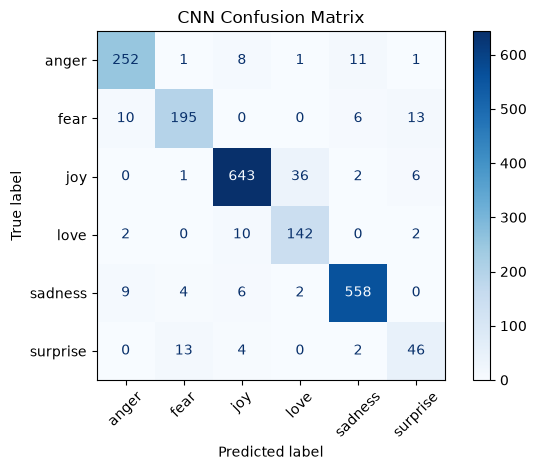

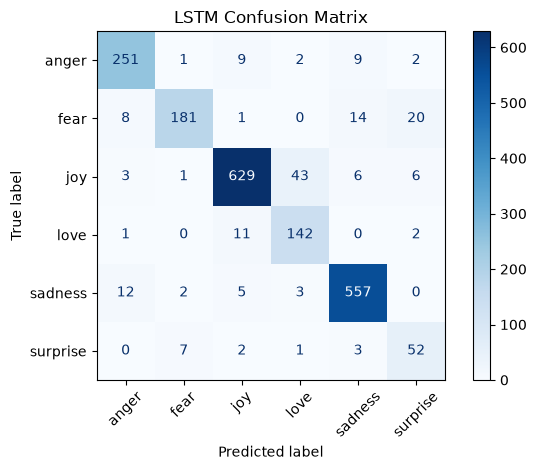

In [36]:
from sklearn.metrics import ConfusionMatrixDisplay

os.makedirs("results", exist_ok=True)

# CNN confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    cnn_test_pred,
    display_labels=label_encoder.classes_,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("CNN Confusion Matrix")
plt.tight_layout()
plt.savefig("results/cnn_confusion_matrix.png", dpi=300)
plt.show()

# LSTM confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    lstm_test_pred,
    display_labels=label_encoder.classes_,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("LSTM Confusion Matrix")
plt.tight_layout()
plt.savefig("results/lstm_confusion_matrix.png", dpi=300)
plt.show()


In [37]:
# Create dataframe for error analysis
errors_df = test_df[["text", "emotion"]].copy()

errors_df["CNN Prediction"] = label_encoder.inverse_transform(
    cnn_test_pred
)

errors_df["LSTM Prediction"] = label_encoder.inverse_transform(
    lstm_test_pred
)

# CNN mistakes
cnn_errors = errors_df[
    errors_df["emotion"] != errors_df["CNN Prediction"]
]

# LSTM mistakes
lstm_errors = errors_df[
    errors_df["emotion"] != errors_df["LSTM Prediction"]
]

print("CNN incorrect predictions:", len(cnn_errors))
print("LSTM incorrect predictions:", len(lstm_errors))

print("\nCNN mistakes:")
display(cnn_errors.head(10))

print("\nLSTM mistakes:")
display(lstm_errors.head(10))


CNN incorrect predictions: 150
LSTM incorrect predictions: 174

CNN mistakes:


,text,emotion,CNN Prediction,LSTM Prediction
6,i felt anger when at the end of a telephone call,anger,joy,joy
10,i don t feel particularly agitated,fear,anger,fear
12,i pay attention it deepens into a feeling of b...,fear,sadness,sadness
36,i feel very honoured to be included in a magzi...,joy,surprise,joy
40,i feel if i completely hated things i d exerci...,anger,sadness,joy
62,i spent wandering around still kinda dazed and...,joy,surprise,surprise
67,i feel a bit stressed even though all the thin...,anger,sadness,sadness
92,i was feeling weird the other day and it went ...,fear,surprise,surprise
93,when a friend dropped a frog down my neck,anger,sadness,anger
102,i feel agitated with myself that i did not for...,fear,anger,anger



LSTM mistakes:


,text,emotion,CNN Prediction,LSTM Prediction
6,i felt anger when at the end of a telephone call,anger,joy,joy
12,i pay attention it deepens into a feeling of b...,fear,sadness,sadness
20,im not sure the feeling of loss will ever go a...,sadness,sadness,love
40,i feel if i completely hated things i d exerci...,anger,sadness,joy
62,i spent wandering around still kinda dazed and...,joy,surprise,surprise
67,i feel a bit stressed even though all the thin...,anger,sadness,sadness
92,i was feeling weird the other day and it went ...,fear,surprise,surprise
102,i feel agitated with myself that i did not for...,fear,anger,anger
107,i looked at mabel this morning i named my left...,fear,surprise,surprise
120,made a wonderfull new friend,joy,sadness,anger


In [38]:
# Save comparison table
test_comparison.to_csv(
    "results/model_comparison.csv",
    index=False
)

# Save vocabulary and label mapping for future predictions
np.save(
    "models/vocabulary.npy",
    np.array(vectorizer.get_vocabulary(), dtype=str)
)

np.save(
    "models/emotion_labels.npy",
    label_encoder.classes_
)

print("All evaluation files saved successfully!")


All evaluation files saved successfully!


In [39]:
#Test the Trained Models with My Own Sentences

In [40]:
def predict_emotion(text, model):
    # Clean the input text
    cleaned_text = clean_text(text)

    if not cleaned_text:
        raise ValueError("Please enter a sentence.")

    # Convert text to numerical sequence
    sequence = vectorizer(
        tf.constant([cleaned_text])
    )

    # Predict emotion probabilities
    predictions = model.predict(
        sequence, verbose=0
    )

    # Get predicted class
    predicted_class = np.argmax(
        predictions[0]
    )

    # Convert class number to emotion label
    emotion = label_encoder.inverse_transform(
        [predicted_class]
    )[0]

    # Get predicted class probability
    probability = predictions[0][predicted_class]

    return emotion, probability


In [41]:
#CNN
sentence = "I am so happy that I passed my exam"

emotion, probability = predict_emotion(
    sentence,
    cnn_model
)

print("Sentence:", sentence)
print("Predicted Emotion:", emotion)
print("Probability:", round(float(probability) * 100, 2), "%")


Sentence: I am so happy that I passed my exam
Predicted Emotion: joy
Probability: 86.66 %


In [42]:
sentence2 = "I am so sad that I did not pass my exam"

emotion, probability = predict_emotion(
    sentence2,
    cnn_model
)

print("Sentence:", sentence2)
print("Predicted Emotion:", emotion)
print("Probability:", round(float(probability) * 100, 2), "%")


Sentence: I am so sad that I did not pass my exam
Predicted Emotion: sadness
Probability: 92.61 %


In [43]:
sentences = [
    "I am so happy today",
    "I feel lonely and depressed",
    "I am extremely angry about this",
    "I am scared of the darkness",
    "I love spending time with you",
    "I never expected this to happen"
]

results = []

for sentence in sentences:

    cnn_emotion, cnn_prob = predict_emotion(
        sentence, cnn_model
    )

    lstm_emotion, lstm_prob = predict_emotion(
        sentence, lstm_model
    )

    results.append({
        "Sentence": sentence,
        "CNN Emotion": cnn_emotion,
        "CNN Probability": round(float(cnn_prob), 3),
        "LSTM Emotion": lstm_emotion,
        "LSTM Probability": round(float(lstm_prob), 3)
    })

prediction_df = pd.DataFrame(results)

display(prediction_df)


,Sentence,CNN Emotion,CNN Probability,LSTM Emotion,LSTM Probability
0,I am so happy today,joy,0.928,joy,0.774
1,I feel lonely and depressed,sadness,0.994,sadness,0.999
2,I am extremely angry about this,anger,0.963,anger,0.956
3,I am scared of the darkness,fear,0.981,fear,0.949
4,I love spending time with you,joy,0.246,love,0.233
5,I never expected this to happen,joy,0.239,anger,0.376


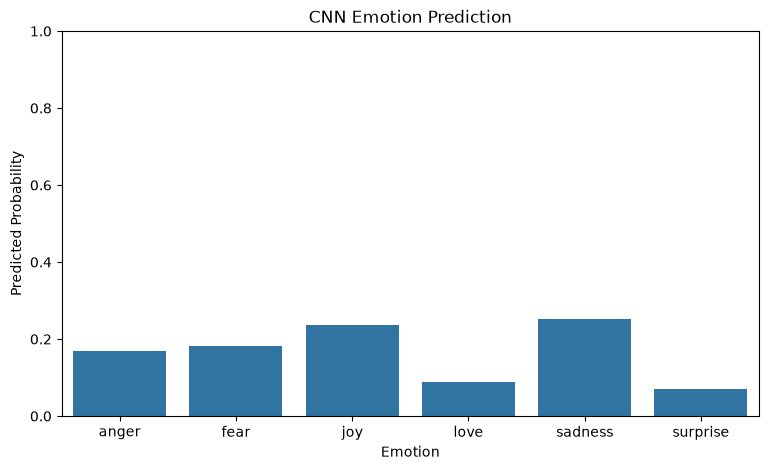

Predicted Emotion: sadness


In [45]:
sentence = "I feel so blue today"

# Preprocess input
cleaned = clean_text(sentence)
sequence = vectorizer(tf.constant([cleaned]))

# Get CNN probabilities
probabilities = cnn_model.predict(
    sequence, verbose=0
)[0]

# Visualize
plt.figure(figsize=(9, 5))

sns.barplot(
    x=label_encoder.classes_,
    y=probabilities
)

plt.title("CNN Emotion Prediction")
plt.xlabel("Emotion")
plt.ylabel("Predicted Probability")
plt.ylim(0, 1)
plt.show()

# Final prediction
predicted_index = np.argmax(probabilities)

print("Predicted Emotion:",
      label_encoder.classes_[predicted_index])
